In [1]:
!pip install -q -U kagglehub

In [2]:
import kagglehub

path = kagglehub.dataset_download(
    "sovitrath/diabetic-retinopathy-2015-data-colored-resized"
)

print("Dataset downloaded to:")
print(path)

100%|██████████| 1.94G/1.94G [00:17<00:00, 120MB/s]

Extracting files...


Dataset downloaded to:
/root/.cache/kagglehub/datasets/sovitrath/diabetic-retinopathy-2015-data-colored-resized/versions/2


In [3]:
import os

for item in os.listdir(path):
    print(item)

colored_images
trainLabels.csv


In [4]:
import pandas as pd

labels = pd.read_csv(os.path.join(path, "trainLabels.csv"))

print(labels.head())
print("\nClass distribution:")
print(labels["level"].value_counts().sort_index())

      image  level
0   10_left      0
1  10_right      0
2   13_left      0
3  13_right      0
4   15_left      1

Class distribution:
level
0    25810
1     2443
2     5292
3      873
4      708
Name: count, dtype: int64


In [5]:
import os

image_path = os.path.join(path, "colored_images")

print(os.listdir(image_path))


['colored_images']


In [6]:
import os

for item in os.listdir(os.path.join(path, "colored_images")):
    print(item)

colored_images


In [7]:
import os

folder = os.path.join(path, "colored_images", "colored_images")

print(os.listdir(folder))

['No_DR', 'Proliferate_DR', 'Moderate', 'Severe', 'Mild']


In [8]:
import os

folder = os.path.join(path, "colored_images", "colored_images")

for class_name in os.listdir(folder):
    class_path = os.path.join(folder, class_name)
    print(class_name, ":", len(os.listdir(class_path)))

No_DR : 25810
Proliferate_DR : 708
Moderate : 5292
Severe : 873
Mild : 2443


In [9]:
import os
import random
import shutil

source = os.path.join(path, "colored_images", "colored_images")
balanced_path = "/content/balanced_dataset"

classes = {
    "No_DR": 0,
    "Mild": 1,
    "Moderate": 2,
    "Severe": 3,
    "Proliferate_DR": 4
}

random.seed(42)

for class_name in classes:
    src = os.path.join(source, class_name)
    dst = os.path.join(balanced_path, class_name)
    os.makedirs(dst, exist_ok=True)

    images = os.listdir(src)
    selected = random.sample(images, 700)

    for image in selected:
        shutil.copy2(
            os.path.join(src, image),
            os.path.join(dst, image)
        )

print("Balanced dataset created successfully!")
print("Total images:", 3500)

Balanced dataset created successfully!
Total images: 3500


In [10]:
import tensorflow as tf

data_dir = "/content/balanced_dataset"

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

print("Classes:", train_ds.class_names)

Found 3500 files belonging to 5 classes.
Using 2800 files for training.
Found 3500 files belonging to 5 classes.
Using 700 files for validation.
Classes: ['Mild', 'Moderate', 'No_DR', 'Proliferate_DR', 'Severe']


In [11]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipeline ready!")

Dataset pipeline ready!


In [12]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [13]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1./127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 29s 186ms/step - accuracy: 0.3118 - loss: 1.5627 - val_accuracy: 0.3286 - val_loss: 1.4368
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.3750 - loss: 1.3897 - val_accuracy: 0.3557 - val_loss: 1.4017
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.3979 - loss: 1.3495 - val_accuracy: 0.3829 - val_loss: 1.3666
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.4104 - loss: 1.3281 - val_accuracy: 0.3743 - val_loss: 1.3428
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.4268 - loss: 1.2916 - val_accuracy: 0.4043 - val_loss: 1.3309
Epoch 6/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.4418 - loss: 1.2692 - val_accuracy: 0.4057 - val_loss: 1.3260
Epoch 7/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.4500 - loss: 1.2541 - val_accuracy: 0.3971 - val_loss: 1.3437
Epoch 8/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.4564 - loss: 1.2301 - val_accuracy: 0.3814 -

In [15]:
base_model.trainable = True

# Freeze the earlier layers and fine-tune the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Trainable layers: 30


In [16]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [17]:
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 33s 195ms/step - accuracy: 0.3746 - loss: 1.6352 - val_accuracy: 0.4143 - val_loss: 1.3453
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.4032 - loss: 1.4471 - val_accuracy: 0.4271 - val_loss: 1.3438
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.4179 - loss: 1.3692 - val_accuracy: 0.4257 - val_loss: 1.3295
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.4407 - loss: 1.2980 - val_accuracy: 0.4257 - val_loss: 1.3176
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.4611 - loss: 1.2476 - val_accuracy: 0.4357 - val_loss: 1.3138
Epoch 6/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.4807 - loss: 1.2141 - val_accuracy: 0.4343 - val_loss: 1.3128
Epoch 7/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.4811 - loss: 1.1783 - val_accuracy: 0.4314 - val_loss: 1.3102
Epoch 8/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 69ms/step - accuracy: 0.5093 - loss: 1.1465 - val_accuracy: 0.4314 

In [18]:
print("Final training accuracy:",
      history_fine.history["accuracy"][-1])

print("Final validation accuracy:",
      history_fine.history["val_accuracy"][-1])

print("Best validation accuracy:",
      max(history_fine.history["val_accuracy"]))

Final training accuracy: 0.5135714411735535
Final validation accuracy: 0.4342857003211975
Best validation accuracy: 0.4357142746448517


In [19]:
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions completed!")
print("Total validation images:", len(y_true))


Predictions completed!
Total validation images: 700


In [20]:
from sklearn.metrics import classification_report

class_names = [
    "Mild",
    "Moderate",
    "No_DR",
    "Proliferate_DR",
    "Severe"
]

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

                precision    recall  f1-score   support

          Mild     0.3116    0.5317    0.3930       126
      Moderate     0.2941    0.1389    0.1887       144
         No_DR     0.4274    0.3521    0.3861       142
Proliferate_DR     0.6013    0.7308    0.6597       130
        Severe     0.5070    0.4557    0.4800       158

      accuracy                         0.4343       700
     macro avg     0.4283    0.4418    0.4215       700
  weighted avg     0.4294    0.4343    0.4187       700



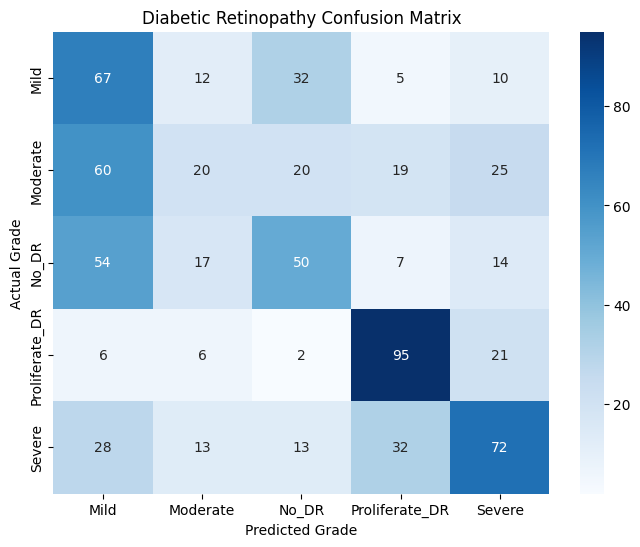

In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")
plt.title("Diabetic Retinopathy Confusion Matrix")
plt.show()

In [22]:
model.save("/content/diabetic_retinopathy_model.keras")

print("Model saved successfully!")

Model saved successfully!


Actual class: Proliferate_DR
Image: 28257_right.png


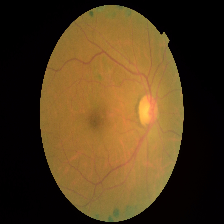

In [23]:
import random
from PIL import Image

# Pick one image from the validation dataset
class_name = random.choice(class_names)
class_folder = os.path.join(
    "/content/balanced_dataset",
    class_name
)

image_file = random.choice(os.listdir(class_folder))
image_path = os.path.join(class_folder, image_file)

print("Actual class:", class_name)
print("Image:", image_file)

img = Image.open(image_path)
display(img)

In [24]:
import numpy as np

img_array = np.array(img.resize((224, 224))) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

print("Actual Grade      :", class_name)
print("Predicted Grade   :", predicted_class)
print("Confidence        :", f"{confidence:.2f}%")

Actual Grade      : Proliferate_DR
Predicted Grade   : No_DR
Confidence        : 58.83%


In [25]:
for i, class_name in enumerate(class_names):
    print(f"{class_name:18s}: {prediction[0][i] * 100:.2f}%")

Mild              : 23.79%
Moderate          : 10.29%
No_DR             : 58.83%
Proliferate_DR    : 1.96%
Severe            : 5.13%


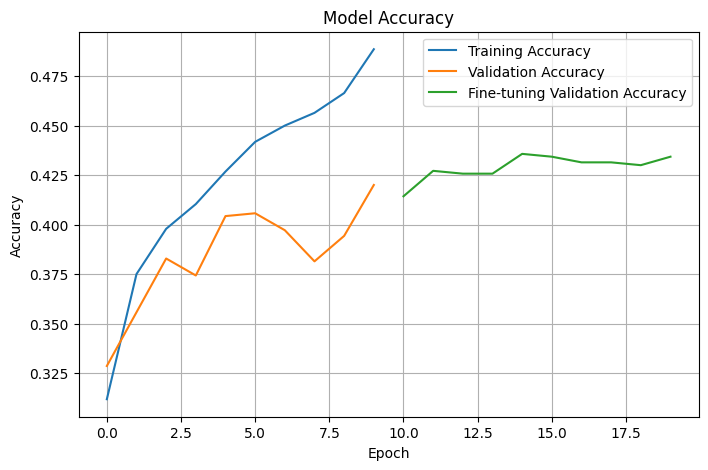

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.plot(
    range(10, 20),
    history_fine.history["val_accuracy"],
    label="Fine-tuning Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
plt.savefig("/content/model_accuracy.png", dpi=300, bbox_inches="tight")
print("Accuracy graph saved successfully!")

Accuracy graph saved successfully!


<Figure size 640x480 with 0 Axes>

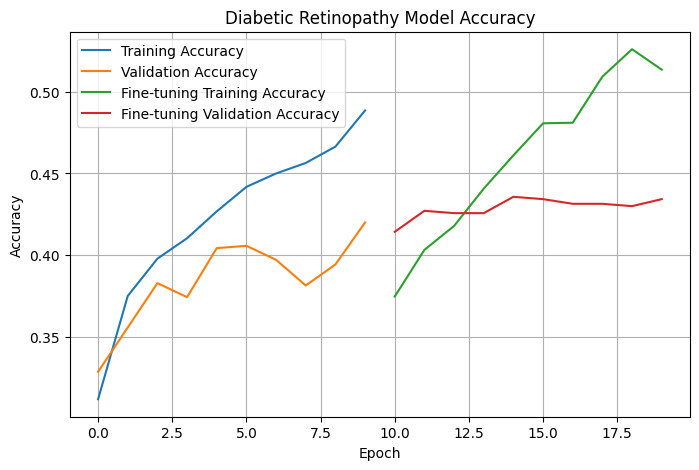

Accuracy graph saved correctly!


In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.plot(
    range(10, 20),
    history_fine.history["accuracy"],
    label="Fine-tuning Training Accuracy"
)

plt.plot(
    range(10, 20),
    history_fine.history["val_accuracy"],
    label="Fine-tuning Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Diabetic Retinopathy Model Accuracy")
plt.legend()
plt.grid(True)

plt.savefig("/content/model_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

print("Accuracy graph saved correctly!")

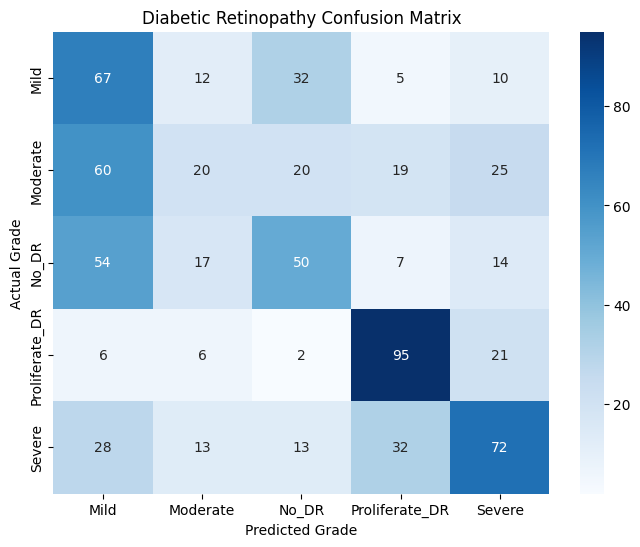

Confusion matrix saved correctly!


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")
plt.title("Diabetic Retinopathy Confusion Matrix")

plt.savefig(
    "/content/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved correctly!")

In [30]:
def predict_dr(image_path):
    from PIL import Image
    import numpy as np

    img = Image.open(image_path).convert("RGB")
    img_resized = img.resize((224, 224))

    img_array = np.array(img_resized) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    display(img)

    print("Predicted Grade :", predicted_class)
    print("Confidence      :", f"{confidence:.2f}%")

    return predicted_class, confidence

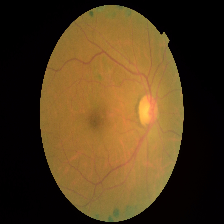

Predicted Grade : No_DR
Confidence      : 58.83%


('No_DR', np.float32(58.83359))

In [31]:
predict_dr(image_path)

In [32]:
!pip install -q gradio

In [33]:
import gradio as gr

def predict_uploaded_image(image):
    image = image.convert("RGB")
    image_resized = image.resize((224, 224))

    img_array = np.array(image_resized) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    return f"Predicted Grade: {predicted_class}\nConfidence: {confidence:.2f}%"

demo = gr.Interface(
    fn=predict_uploaded_image,
    inputs=gr.Image(type="pil", label="Upload Retinal Image"),
    outputs=gr.Textbox(label="Prediction"),
    title="Diabetic Retinopathy Grading",
    description="Upload a retinal image to predict the DR grade."
)

print("Interface created successfully!")

Interface created successfully!


In [36]:
from google.colab import files
from PIL import Image
import numpy as np

uploaded = files.upload()

for filename in uploaded.keys():
    img = Image.open(filename).convert("RGB")
    display(img)

    img_resized = img.resize((224, 224))
    img_array = np.array(img_resized).astype("float32")
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    print("Predicted Grade :", predicted_class)
    print("Confidence      :", f"{confidence:.2f}%")

In [37]:
import os

folder = "/content/balanced_dataset/Proliferate_DR"

files_list = os.listdir(folder)

print("Number of images:", len(files_list))
print("First 10 images:")
print(files_list[:10])

Number of images: 700
First 10 images:
['13222_left.png', '9298_left.png', '37783_right.png', '16802_right.png', '29865_right.png', '41746_left.png', '13038_right.png', '22568_left.png', '37951_left.png', '34453_right.png']


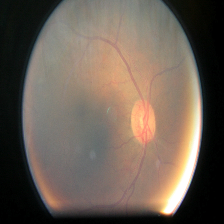

In [38]:
image_path = "/content/balanced_dataset/Proliferate_DR/13222_left.png"

from PIL import Image

img = Image.open(image_path)
display(img)

In [39]:
import numpy as np

img_resized = img.resize((224, 224))
img_array = np.array(img_resized).astype("float32")
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

print("Predicted Grade :", predicted_class)
print("Confidence      :", f"{confidence:.2f}%")

Predicted Grade : Proliferate_DR
Confidence      : 55.52%


In [40]:
grade_names = {
    "No_DR": "Grade 0 - No Diabetic Retinopathy",
    "Mild": "Grade 1 - Mild Diabetic Retinopathy",
    "Moderate": "Grade 2 - Moderate Diabetic Retinopathy",
    "Severe": "Grade 3 - Severe Diabetic Retinopathy",
    "Proliferate_DR": "Grade 4 - Proliferative Diabetic Retinopathy"
}

print("Predicted Result :", grade_names[predicted_class])
print("Confidence       :", f"{confidence:.2f}%")

Predicted Result : Grade 4 - Proliferative Diabetic Retinopathy
Confidence       : 55.52%


In [42]:
import os

source = os.path.join(path, "colored_images", "colored_images")

classes = ["No_DR", "Mild", "Moderate", "Severe", "Proliferate_DR"]

for class_name in classes:
    original = set(os.listdir(os.path.join(source, class_name)))
    used = set(os.listdir(os.path.join("/content/balanced_dataset", class_name)))

    available = original - used

    print(class_name, "→", len(available), "unused images")

No_DR → 25110 unused images
Mild → 1743 unused images
Moderate → 4592 unused images
Severe → 173 unused images
Proliferate_DR → 8 unused images


In [43]:
import os
import random
import shutil

test_path = "/content/test_dataset"

source = os.path.join(path, "colored_images", "colored_images")

classes = {
    "No_DR": 20,
    "Mild": 20,
    "Moderate": 20,
    "Severe": 20,
    "Proliferate_DR": 8
}

random.seed(123)

for class_name, number in classes.items():

    src = os.path.join(source, class_name)
    dst = os.path.join(test_path, class_name)

    os.makedirs(dst, exist_ok=True)

    used_images = set(
        os.listdir(os.path.join("/content/balanced_dataset", class_name))
    )

    available = [
        f for f in os.listdir(src)
        if f not in used_images
    ]

    selected = random.sample(available, number)

    for image in selected:
        shutil.copy2(
            os.path.join(src, image),
            os.path.join(dst, image)
        )

print("Separate test dataset created successfully!\n")

for class_name in classes:
    count = len(os.listdir(os.path.join(test_path, class_name)))
    print(class_name, ":", count)

Separate test dataset created successfully!

No_DR : 20
Mild : 20
Moderate : 20
Severe : 20
Proliferate_DR : 8


In [44]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

test_images = []
test_labels = []

for class_name, grade in classes.items():
    folder = os.path.join(test_path, class_name)

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        img = Image.open(image_path).convert("RGB")
        img = img.resize((224, 224))

        img_array = np.array(img).astype("float32")

        test_images.append(img_array)
        test_labels.append(grade)

test_images = np.array(test_images)
test_labels = np.array(test_labels)

predictions = model.predict(test_images, verbose=0)
test_pred = np.argmax(predictions, axis=1)

test_accuracy = accuracy_score(test_labels, test_pred)

print("Test Images :", len(test_images))
print("Test Accuracy :", f"{test_accuracy * 100:.2f}%")

Test Images : 88
Test Accuracy : 0.00%


In [45]:
class_to_index = {
    "Mild": 0,
    "Moderate": 1,
    "No_DR": 2,
    "Proliferate_DR": 3,
    "Severe": 4
}

test_labels = []

for class_name in classes:
    folder = os.path.join(test_path, class_name)

    for filename in os.listdir(folder):
        test_labels.append(class_to_index[class_name])

test_labels = np.array(test_labels)

test_accuracy = accuracy_score(test_labels, test_pred)

print("Test Images :", len(test_labels))
print("Correct Predictions :", np.sum(test_labels == test_pred))
print("Test Accuracy :", f"{test_accuracy * 100:.2f}%")

Test Images : 88
Correct Predictions : 29
Test Accuracy : 32.95%


In [46]:
from google.colab import files

files.download("/content/test_dataset/Proliferate_DR/" + os.listdir("/content/test_dataset/Proliferate_DR")[0])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving 32148_left.png to 32148_left.png


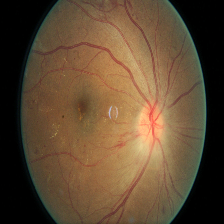

DIABETIC RETINOPATHY PREDICTION
Predicted Result : Grade 3 - Severe Diabetic Retinopathy
Confidence       : 55.34%
Overall Test Accuracy : 32.95%


In [47]:
from google.colab import files
from PIL import Image
import numpy as np

uploaded = files.upload()

for filename in uploaded.keys():

    img = Image.open(filename).convert("RGB")
    display(img)

    # Prepare image
    img_resized = img.resize((224, 224))
    img_array = np.array(img_resized).astype("float32")
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    grade_names = {
        "No_DR": "Grade 0 - No Diabetic Retinopathy",
        "Mild": "Grade 1 - Mild Diabetic Retinopathy",
        "Moderate": "Grade 2 - Moderate Diabetic Retinopathy",
        "Severe": "Grade 3 - Severe Diabetic Retinopathy",
        "Proliferate_DR": "Grade 4 - Proliferative Diabetic Retinopathy"
    }

    print("======================================")
    print("DIABETIC RETINOPATHY PREDICTION")
    print("======================================")
    print("Predicted Result :", grade_names[predicted_class])
    print("Confidence       :", f"{confidence:.2f}%")
    print("Overall Test Accuracy : 32.95%")
    print("======================================")

In [48]:
for layer in base_model.layers[-10:]:
    print(layer.name, layer.output.shape)

block_16_expand_BN (None, 7, 7, 960)
block_16_expand_relu (None, 7, 7, 960)
block_16_depthwise (None, 7, 7, 960)
block_16_depthwise_BN (None, 7, 7, 960)
block_16_depthwise_relu (None, 7, 7, 960)
block_16_project (None, 7, 7, 320)
block_16_project_BN (None, 7, 7, 320)
Conv_1 (None, 7, 7, 1280)
Conv_1_bn (None, 7, 7, 1280)
out_relu (None, 7, 7, 1280)


In [49]:
gradcam_layer = base_model.get_layer("out_relu")

print("Grad-CAM layer:", gradcam_layer.name)
print("Output shape:", gradcam_layer.output.shape)


Grad-CAM layer: out_relu
Output shape: (None, 7, 7, 1280)


In [51]:
import tensorflow as tf

# Build a Grad-CAM model using the actual input tensor
grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        base_model.get_layer("out_relu").output,
        model.layers[-1].output
    ]
)

print("Grad-CAM model created successfully!")

Grad-CAM model created successfully!


In [53]:
# Rebuild the model as a Functional model for Grad-CAM

inputs = tf.keras.Input(shape=(224, 224, 3))

x = model.layers[1](inputs)          # MobileNetV2 base model
x = model.layers[2](x)               # GlobalAveragePooling2D
x = model.layers[3](x)               # Dropout
x = model.layers[4](x)               # Dense(128)
x = model.layers[5](x)               # Dropout
outputs = model.layers[6](x)         # Dense(5)

gradcam_functional = tf.keras.Model(inputs, outputs)

print("Grad-CAM compatible model created successfully!")

Grad-CAM compatible model created successfully!


In [55]:
model.save("/content/diabetic_retinopathy_model_backup.keras")

print("Backup saved successfully!")

Backup saved successfully!


In [56]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

print("Data augmentation created successfully!")

Data augmentation created successfully!


In [57]:
from tensorflow.keras import models, layers

improved_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax")
])

# Start with MobileNetV2 frozen
base_model.trainable = False

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved model created successfully!")

Improved model created successfully!


In [58]:
history_improved = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 21s 103ms/step - accuracy: 0.3146 - loss: 1.5751 - val_accuracy: 0.3414 - val_loss: 1.4094
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.3804 - loss: 1.4035 - val_accuracy: 0.3686 - val_loss: 1.3660
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.3900 - loss: 1.3680 - val_accuracy: 0.3743 - val_loss: 1.3550
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.4029 - loss: 1.3354 - val_accuracy: 0.3871 - val_loss: 1.3456
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.4168 - loss: 1.3243 - val_accuracy: 0.3771 - val_loss: 1.3447
Epoch 6/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.4132 - loss: 1.3183 - val_accuracy: 0.3914 - val_loss: 1.3292
Epoch 7/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.4293 - loss: 1.2914 - val_accuracy: 0.3529 - val_loss: 1.3810
Epoch 8/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.4350 - loss: 1.2949 - val_accuracy: 0.3857

In [59]:
base_model.trainable = True

# Keep most layers frozen; fine-tune the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning ready!")
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Fine-tuning ready!
Trainable layers: 30


In [60]:
history_fine_improved = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 23s 119ms/step - accuracy: 0.4225 - loss: 1.3169 - val_accuracy: 0.4057 - val_loss: 1.3064
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 18s 96ms/step - accuracy: 0.4500 - loss: 1.2630 - val_accuracy: 0.4186 - val_loss: 1.3010
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.4254 - loss: 1.2678 - val_accuracy: 0.4129 - val_loss: 1.2960
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.4479 - loss: 1.2487 - val_accuracy: 0.4086 - val_loss: 1.2931
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.4504 - loss: 1.2412 - val_accuracy: 0.4157 - val_loss: 1.2849
Epoch 6/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.4654 - loss: 1.2290 - val_accuracy: 0.4129 - val_loss: 1.2858
Epoch 7/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.4589 - loss: 1.2295 - val_accuracy: 0.4257 - val_loss: 1.2694
Epoch 8/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.4561 - loss: 1.2231 - val_accuracy: 0.43

In [61]:
best_epoch = np.argmax(history_fine_improved.history["val_accuracy"]) + 1
best_val_acc = max(history_fine_improved.history["val_accuracy"])

print("Best Epoch :", best_epoch)
print("Best Validation Accuracy :", f"{best_val_acc * 100:.2f}%")

Best Epoch : 8
Best Validation Accuracy : 43.00%


In [62]:
improved_model.save("/content/diabetic_retinopathy_improved_model.keras")

print("Improved model saved successfully!")

Improved model saved successfully!


In [63]:
from collections import Counter

train_counts = Counter()

for _, labels in train_ds:
    train_counts.update(labels.numpy().tolist())

print("Training class distribution:")
for i, name in enumerate(class_names):
    print(f"{name}: {train_counts[i]}")

Training class distribution:
Mild: 574
Moderate: 556
No_DR: 558
Proliferate_DR: 570
Severe: 542


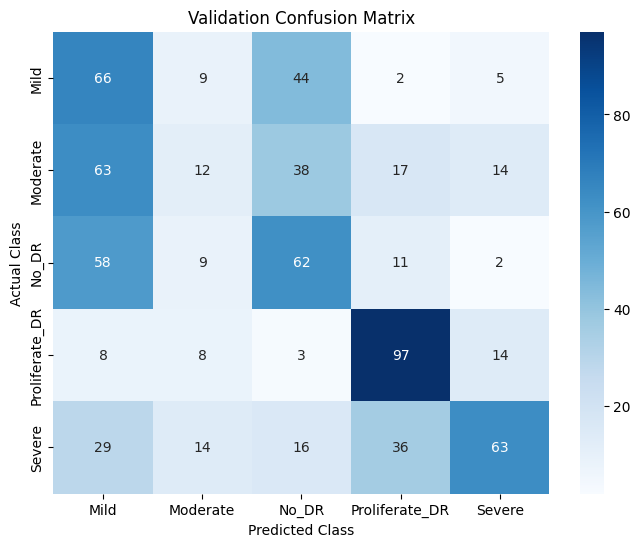

In [64]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = improved_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Validation Confusion Matrix")
plt.show()

In [65]:
print("Confusion Matrix:")
print(cm)

print("\nClass order:")
print(class_names)

Confusion Matrix:
[[66  9 44  2  5]
 [63 12 38 17 14]
 [58  9 62 11  2]
 [ 8  8  3 97 14]
 [29 14 16 36 63]]

Class order:
['Mild', 'Moderate', 'No_DR', 'Proliferate_DR', 'Severe']


Saving 32148_left.png to 32148_left (1).png


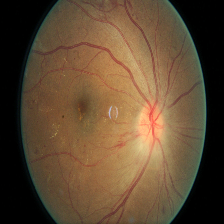


   DIABETIC RETINOPATHY GRADING
Image            : 32148_left (1).png
Predicted Result : Grade 3 - Severe Diabetic Retinopathy
Confidence       : 45.47%
Validation Accuracy : 43.43%
Note: This is a deep-learning screening
prototype and not a medical diagnosis.


In [66]:
from google.colab import files
from PIL import Image
import numpy as np

# Upload retinal image
uploaded = files.upload()

grade_names = {
    "No_DR": "Grade 0 - No Diabetic Retinopathy",
    "Mild": "Grade 1 - Mild Diabetic Retinopathy",
    "Moderate": "Grade 2 - Moderate Diabetic Retinopathy",
    "Severe": "Grade 3 - Severe Diabetic Retinopathy",
    "Proliferate_DR": "Grade 4 - Proliferative Diabetic Retinopathy"
}

for filename in uploaded.keys():

    # Read image
    img = Image.open(filename).convert("RGB")
    display(img)

    # Resize
    img_resized = img.resize((224, 224))

    # IMPORTANT: keep pixel values 0-255
    # The model already performs Rescaling internally
    img_array = np.array(img_resized).astype("float32")
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    print("\n==========================================")
    print("   DIABETIC RETINOPATHY GRADING")
    print("==========================================")
    print("Image            :", filename)
    print("Predicted Result :", grade_names[predicted_class])
    print("Confidence       :", f"{confidence:.2f}%")
    print("Validation Accuracy : 43.43%")
    print("==========================================")
    print("Note: This is a deep-learning screening")
    print("prototype and not a medical diagnosis.")

In [67]:
from google.colab import files

files.download("/content/diabetic_retinopathy_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>